In [3]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/rabieelkharoua/predict-conversion-in-digital-marketing-dataset/digital_marketing_campaign_dataset.csv


In [4]:
import pandas as pd 

df = pd.read_csv('/kaggle/input/datasets/rabieelkharoua/predict-conversion-in-digital-marketing-dataset/digital_marketing_campaign_dataset.csv')
df.head(10)

,CustomerID,Age,Gender,Income,CampaignChannel,CampaignType,AdSpend,ClickThroughRate,ConversionRate,WebsiteVisits,PagesPerVisit,TimeOnSite,SocialShares,EmailOpens,EmailClicks,PreviousPurchases,LoyaltyPoints,AdvertisingPlatform,AdvertisingTool,Conversion
0,8000,56,Female,136912,Social Media,Awareness,6497.870068,0.043919,0.088031,0,2.399017,7.396803,19,6,9,4,688,IsConfid,ToolConfid,1
1,8001,69,Male,41760,Email,Retention,3898.668606,0.155725,0.182725,42,2.917138,5.352549,5,2,7,2,3459,IsConfid,ToolConfid,1
2,8002,46,Female,88456,PPC,Awareness,1546.429596,0.277490,0.076423,2,8.223619,13.794901,0,11,2,8,2337,IsConfid,ToolConfid,1
3,8003,32,Female,44085,PPC,Conversion,539.525936,0.137611,0.088004,47,4.540939,14.688363,89,2,2,0,2463,IsConfid,ToolConfid,1
4,8004,60,Female,83964,PPC,Conversion,1678.043573,0.252851,0.109940,0,2.046847,13.993370,6,6,6,8,4345,IsConfid,ToolConfid,1
5,8005,25,Female,42925,Social Media,Awareness,9579.388247,0.153795,0.161316,6,2.125850,7.752831,95,5,8,0,3316,IsConfid,ToolConfid,1
6,8006,38,Female,25615,Referral,Awareness,7302.899852,0.040975,0.060977,42,1.753995,10.698672,54,14,3,6,930,IsConfid,ToolConfid,1
7,8007,56,Female,57083,Social Media,Conversion,5324.283667,0.052878,0.188946,48,2.626015,2.987817,96,9,3,0,2983,IsConfid,ToolConfid,1
8,8008,36,Female,140788,Email,Retention,9421.250951,0.023536,0.112585,13,5.472843,14.287421,73,4,8,5,460,IsConfid,ToolConfid,1
9,8009,40,Male,130764,Social Media,Awareness,6229.193333,0.066641,0.169786,22,1.135665,4.613312,14,8,4,8,3789,IsConfid,ToolConfid,1


In [5]:
df.shape

(8000, 20)

In [6]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 20 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   CustomerID           8000 non-null   int64  
 1   Age                  8000 non-null   int64  
 2   Gender               8000 non-null   object 
 3   Income               8000 non-null   int64  
 4   CampaignChannel      8000 non-null   object 
 5   CampaignType         8000 non-null   object 
 6   AdSpend              8000 non-null   float64
 7   ClickThroughRate     8000 non-null   float64
 8   ConversionRate       8000 non-null   float64
 9   WebsiteVisits        8000 non-null   int64  
 10  PagesPerVisit        8000 non-null   float64
 11  TimeOnSite           8000 non-null   float64
 12  SocialShares         8000 non-null   int64  
 13  EmailOpens           8000 non-null   int64  
 14  EmailClicks          8000 non-null   int64  
 15  PreviousPurchases    8000 non-null   i

In [7]:
df.isnull().sum()

CustomerID             0
Age                    0
Gender                 0
Income                 0
CampaignChannel        0
CampaignType           0
AdSpend                0
ClickThroughRate       0
ConversionRate         0
WebsiteVisits          0
PagesPerVisit          0
TimeOnSite             0
SocialShares           0
EmailOpens             0
EmailClicks            0
PreviousPurchases      0
LoyaltyPoints          0
AdvertisingPlatform    0
AdvertisingTool        0
Conversion             0
dtype: int64

In [8]:
df['Conversion'].value_counts()

Conversion
1    7012
0     988
Name: count, dtype: int64

 ### O dataset apresenta uma alta taxa de conversão, com 7.012 dos 8.000 clientes (87,6%) classificados como convertidos

In [9]:
df.groupby('CampaignChannel')['Conversion']\
.mean()\
.sort_values(ascending=False)

CampaignChannel
Referral        0.883072
PPC             0.882779
SEO             0.876774
Email           0.870263
Social Media    0.868334
Name: Conversion, dtype: float64

### O canal REFERRAL apresentou a maior taxa de conversão (88,31%), seguido por PPC (88,28%). Já o canal social media apresentou a menor taxa de conversão (86,83%). Apesar das diferenças serem pequenas, REFERRAL e PCC demonstraram desempenho ligeiramente superior em relação aos demais canais. 

### As taxas de conversão entre os canais são bem próximas, indicando que nenhum canal se destaca de forma significativa. Isso sugere que outros fatores além do canal de marketing podem estar influenciando as conversões 

In [10]:
df.groupby('CampaignType')\
['Conversion'].mean()\
.sort_values(ascending=False)

CampaignType
Conversion       0.933558
Retention        0.858243
Consideration    0.855634
Awareness        0.855634
Name: Conversion, dtype: float64

### Observação: Os registros associados ao tipo de campanha "Conversion" apresentaram a maior taxa média de conversão(93%), enquanto Awareness e Consideration apresentam as menores taxas (85%).

### Interpretação: Como "CampaignType" parece apresentar objetivos ou estágios do funil de marketing, é esperado que campanhas voltadas para conversão apresentem maior probabilidade de gerar o resultado desejado do que campanhas focadas em awareness ou consideration.

In [11]:
df.groupby('Conversion')[['EmailOpens','EmailClicks']].mean()

,EmailOpens,EmailClicks
Conversion,,
0,7.576923,3.481781
1,9.744581,4.606246


### Os resultados sugerem que o engajamento com campanhas de e-mail está associado a uma maior probabilidade de conversão. Usuarios que interagem mais com as comunicações por e-mail tendem a converter com maior frequência. 

In [12]:
df.groupby('Conversion')\
[['WebsiteVisits','PagesPerVisit','TimeOnSite']].mean()

,WebsiteVisits,PagesPerVisit,TimeOnSite
Conversion,,,
0,21.726721,4.835002,6.267871
1,25.177838,5.649945,7.933413


### Os dados indicam que pessoas que interagem mais com o website tendem a converter com maior frequência. Em média, os clientes convertidos visitam o site mais vezes, visualizam mais páginas e passam mais tempo navegando do que os não convertidos. 

In [13]:
df.groupby('Conversion')\
[['PreviousPurchases','LoyaltyPoints']].mean()

,PreviousPurchases,LoyaltyPoints
Conversion,,
0,3.625506,2128.483806
1,4.606674,2541.244438


### Pessoas que já possuem um histórico de relacionamento tendem a ter maior probabilidade de realizar novas ações, como participar de eventos, abrir e-mails ou renovar sua associação. 

In [14]:
df.groupby ('Conversion')\
['Income'].mean()

Conversion
0    83265.308704
1    84861.301911
Name: Income, dtype: float64

### Rendas sao parecidas entre os que converteram e os que nao converteram

In [15]:
df.groupby('Conversion')['Age'].mean()

Conversion
0    43.561741
1    43.634484
Name: Age, dtype: float64

In [16]:
df.groupby('Age')['Conversion'].mean()

Age
18    0.898649
19    0.846667
20    0.860927
21    0.856250
22    0.870504
23    0.850649
24    0.844961
25    0.888889
26    0.909091
27    0.897059
28    0.915033
29    0.864865
30    0.872611
31    0.891892
32    0.808917
33    0.858108
34    0.836158
35    0.870968
36    0.875817
37    0.884615
38    0.913580
39    0.921212
40    0.911765
41    0.887417
42    0.862275
43    0.915730
44    0.914062
45    0.924855
46    0.890909
47    0.886667
48    0.833333
49    0.838150
50    0.825503
51    0.877419
52    0.860465
53    0.865772
54    0.893750
55    0.881119
56    0.857143
57    0.891720
58    0.881944
59    0.856164
60    0.870504
61    0.880000
62    0.890110
63    0.857143
64    0.930481
65    0.883212
66    0.853933
67    0.897810
68    0.845161
69    0.850340
Name: Conversion, dtype: float64

### A taxa de conversão varia entre as diferentes idades, mas não apresenta uma tendência clara de aumento ou diminuição conforme a idade cresce.

In [17]:
df.corr(numeric_only=True)\
['Conversion'].sort_values(ascending=False)

Conversion           1.000000
TimeOnSite           0.129609
EmailClicks          0.129521
EmailOpens           0.124884
AdSpend              0.124672
ClickThroughRate     0.120012
PreviousPurchases    0.111781
PagesPerVisit        0.102840
LoyaltyPoints        0.095004
ConversionRate       0.093185
WebsiteVisits        0.079339
Income               0.013974
Age                  0.001606
SocialShares        -0.011449
CustomerID          -0.180742
Name: Conversion, dtype: float64

### As variáveis mais relacionadas a conversão foram Timeonsite(0,130), Emailclicks(0,130), emailOpens(0,125), Adspend(0,125), e clickthroughrate(0,120). Apesar de apresentarem correlações positivas, todas foram relativamente fracas, sugerindo que a conversão é influenciada por uma combinação de fatores e não por uma única variável. 

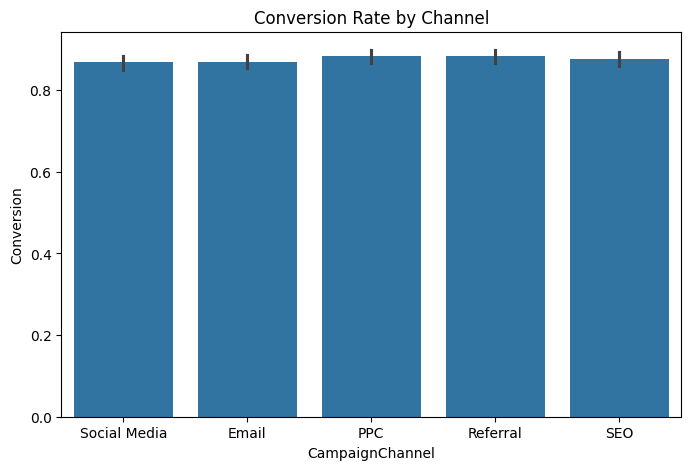

In [18]:
import seaborn as sns 
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

sns.barplot(
    data=df,
    x='CampaignChannel',
    y='Conversion'
)
plt.title('Conversion Rate by Channel')
plt.show()

### Todos os canais tiveram resultados parecidos. Nenhum canal foi claramente melhor ou pior que os demais em termos de conversão. 

In [19]:
df.groupby('Conversion')['AdSpend'].mean()

Conversion
0    4058.398466
1    5133.750850
Name: AdSpend, dtype: float64

### Os clientes que converteram receberam mais investimento em publicidade do que os clientes que não converteram. 

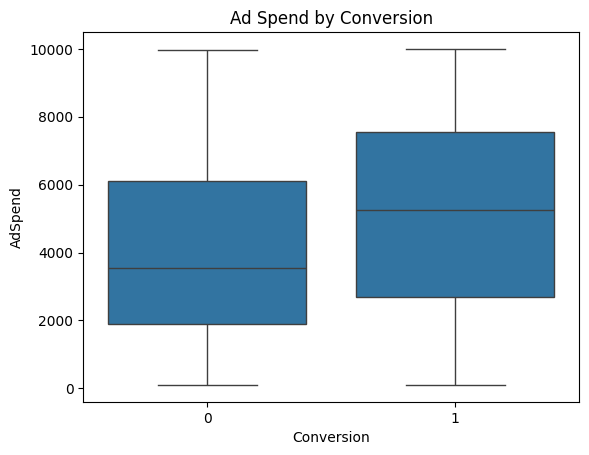

In [20]:
sns.boxplot(
    data=df,
    x='Conversion',
    y='AdSpend'
)
plt.title('Ad Spend by Conversion')
plt.show()

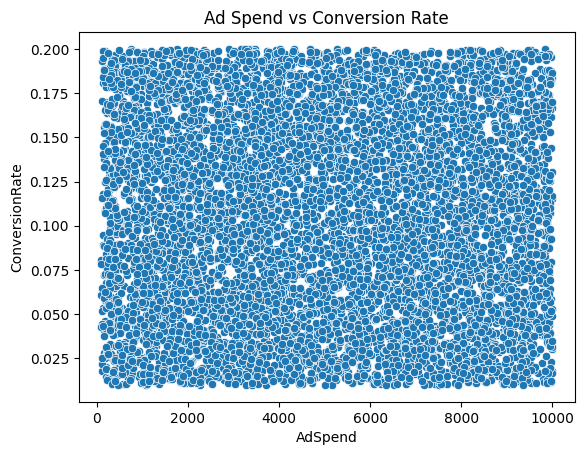

In [21]:
sns.scatterplot(
    data=df,
    x='AdSpend',
    y='ConversionRate'
)
plt.title('Ad Spend vs Conversion Rate')
plt.show()

### Apenas investir mais, não garante uma taxa de conversão maior. Outros fatores podem estar influenciando os resultados das campanhas. 

In [22]:
df[['AdSpend','ConversionRate']].corr()

,AdSpend,ConversionRate
AdSpend,1.000000,-0.020185
ConversionRate,-0.020185,1.000000


### Não foi identificado uma relacao significativa entre o investimento em publicidade (AdSpend) e a taxa de conversao (Conversion Rate)

In [23]:
df.groupby('Gender')\
['Conversion'].mean()\
.sort_values(ascending=False)

Gender
Male      0.876938
Female    0.876214
Name: Conversion, dtype: float64

### Gender has no meaningful impact on conversation in this dataset

In [24]:
df.groupby('CampaignChannel')\
['ClickThroughRate'].mean().sort_values(ascending=False)

CampaignChannel
PPC             0.158307
Email           0.155609
Social Media    0.155523
SEO             0.153150
Referral        0.151673
Name: ClickThroughRate, dtype: float64

### Todos os canais apresentaram níveis de engajamento semelhantes. 

In [25]:
df.groupby('CampaignChannel')\
['ConversionRate'].mean().sort_values(ascending=False)

CampaignChannel
Social Media    0.106550
Email           0.104884
PPC             0.104132
SEO             0.103530
Referral        0.103051
Name: ConversionRate, dtype: float64

### Nenhum canal demonstrou vantagem significativa em relação aos demais. Os resultados sugerem que o canal, por si só, não é o principal fator que influencia a conversão. 

### Pay Per Click 
### Click-Through-Rate

In [26]:
x = df[['Age',
       'Income',
        'AdSpend',
       'ClickThroughRate',
       'ConversionRate',
       'WebsiteVisits',
       'PagesPerVisit',
       'TimeOnSite',
       'SocialShares',
       'EmailOpens',
       'EmailClicks',
       'PreviousPurchases',
       'LoyaltyPoints']]
y = df['Conversion']

In [27]:
x.shape

(8000, 13)

In [28]:
y.shape

(8000,)

In [29]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42
)

In [30]:
x_train.shape

(6400, 13)

In [31]:
x_test.shape

(1600, 13)

In [32]:
y_train.shape

(6400,)

In [33]:
y_test.shape

(1600,)

### O conjunto de dados foi dividido em dados de treinamento (80%) e teste (20%). Os dados de treinamento serão utilizados para ensinar o modelo a identificar padrões relacionados a conversão, enquanto os dados de teste serão utilizados para avaliar a capacidade do modelo de realizar previsões em novos dados. 

In [34]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression(max_iter=1000)
model.fit(x_train, y_train)

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression(max_iter=1000)

In [35]:
predictions = model.predict(x_test)

In [36]:
from sklearn.metrics import accuracy_score
accuracy_score(y_test, predictions)

0.879375

## Regressão Logística

Foi desenvolvido um modelo de regressão logística com o objetivo de prever se um cliente realizará ou não uma conversão, utilizando informações como idade, renda, comportamento no site, interação com e-mails, histórico de compras e pontos de fidelidade.

Para isso, o conjunto de dados foi dividido em:

- 80% para treinamento do modelo
- 20% para teste do modelo

Após o treinamento, o modelo alcançou uma porcentagem de 87,94% na base de teste.

### Observação

O modelo acertou aproximadamente 88 de cada 100 previsões.

### Interpretação inicial

À primeira vista, o resultado parece positivo. No entanto, é importante lembrar que a maioria dos clientes deste conjunto de dados já realizou uma conversão (87,6).

Por esse motivo, a acurácia sozinha não é suficiente para determinar se o modelo realmente possui boa capacidade de previsão. 

### Próximo Passo

Será necessário adicionar métricas adicionais para entender o melhor desempenho do modelo e verificar sua capacidade de identificar corretamente clientes que convertem e clientes que não convertem. 

In [37]:
from sklearn.metrics import confusion_matrix

confusion_matrix(y_test,predictions)

array([[   1,  193],
       [   0, 1406]])

#### O modelo alcançou uma acurácia de 87,94%, porém essa metrica pode ser enganosa devido ao desbalanceamento do conjunto de dados. A matriz de confusao monstrou que o modelo classificou quase todos os clientes que nao converteram. Isso indica que, apesar da alta acurácia, o modelo teve dificuldade em distinguir clientes convertidos de não convertidos, sendo necessária a análise de outras métricas para avaliar melhor seu desempenho. 

In [38]:
from sklearn.metrics import classification_report
print(classification_report(y_test, predictions))

              precision    recall  f1-score   support

           0       1.00      0.01      0.01       194
           1       0.88      1.00      0.94      1406

    accuracy                           0.88      1600
   macro avg       0.94      0.50      0.47      1600
weighted avg       0.89      0.88      0.82      1600



### Observation

O modelo apresentou uma acurácia de 87,94%, mas teve grande dificuldade para identificar clientes que não converteram.

A análise do classification report mostrou que o modelo teve ótimo desempenho para prever clientes convertidos (classe 1), porém, desempenho muito fraco para prever clientes que não converteram (classe 0).

O recall da classe 0 foi de apenas 0,01, indicando que o modelo identificou corretamente apenas uma pequena parcela dos clientes que não converteram. 

### Interpretacao

Os resultados sugerem que o modelo aprendeu a classificar quase todos os clientes como convertidos. Isso aconteceu porque o conjunto de dados é fortemente desbalanceado, com aproximadamente 87% dos registros pertencendo à classe de conversão. 

### Conclusao

Apesar da alta acurácia, o modelo não conseguiu diferenciar adequadamente clientes convertidos e não convertidos. Por esse motivo, a acurácia isoladamente não deve ser utilizada como principal métrica de avaliação neste caso. 

#### Customers who engage more with emails, spend more time on the website, and already have a relationship with the company are more likely to convert, while demographic characteristics such as age, income, and gender appear to have little influence on conversion behavior. 


In [39]:
from sklearn.tree import DecisionTreeClassifier
tree = DecisionTreeClassifier(
    max_depth=4,
    random_state=42
)
tree.fit(x_train,y_train)

DecisionTreeClassifier(max_depth=4, random_state=42)

## Árvore de Decisão 

Foi desenvolvido um modelo de árvore de decisão para prever se um cliente realizará uma conversão.

Diferentemente da regressão logística, a árvore de decisão realiza previsões por meio de uma sequência de regras e decisões baseadas nas características dos clientes.

Para evitar que o modelo fique excessivamente completo, a profundidade máxima da árvore foi limitada a 4 níveis. 

In [40]:
tree_predictions = tree.predict(x_test)


In [41]:
from sklearn.metrics import accuracy_score

accuracy_score(y_test, tree_predictions)

0.879375

### A árvore de decisão apresentou uma acurácia de 87%, o mesmo resultado obtido pelo modelo de regressão logística.

### Isso indica que ambos os modelos tiveram desempenho semelhante ao prever as conversões dos clientes.

In [42]:
from sklearn.metrics import confusion_matrix

confusion_matrix(y_test, tree_predictions)

array([[  42,  152],
       [  41, 1365]])

In [43]:
from sklearn.metrics import classification_report

print(classification_report(y_test,tree_predictions))

              precision    recall  f1-score   support

           0       0.51      0.22      0.30       194
           1       0.90      0.97      0.93      1406

    accuracy                           0.88      1600
   macro avg       0.70      0.59      0.62      1600
weighted avg       0.85      0.88      0.86      1600



### A árvore de decisão apresentou desempenho superior à regressão logística na identificação de clientes que não converteram. 

### Embora ambos os modelos apresentassem acurácia semelhante de 87%, a árvore de decisão conseguiu distinguir melhor clientes convertidos e não convertidos. 

### Os resultados indicam que a árvore de decisão foi o modelo mais equilibrado para esse conjunto de dados. 

In [48]:
import pandas as pd

feature_importance = pd.DataFrame({
    'Feature': x.columns,
    'importance': tree.feature_importances_
})

feature_importance.sort_values(
    by='importance',
    ascending=False
)

,Feature,importance
11,PreviousPurchases,0.182838
6,PagesPerVisit,0.175642
3,ClickThroughRate,0.144173
12,LoyaltyPoints,0.093969
7,TimeOnSite,0.078032
9,EmailOpens,0.077531
10,EmailClicks,0.066959
2,AdSpend,0.063466
5,WebsiteVisits,0.059955
4,ConversionRate,0.057435


## Importância das Variáveis

A Árvore de Decisão identificou **PreviousPurchases**, **PagesPerVisit** e **ClickThroughRate** como os fatores mais importantes para prever a conversão. 

### Interpretação

Os resultados indicam que o **comportamento dos clientes** e o **histórico de relacionamento** foram mais importantes para prever conversões do que características demográficas.





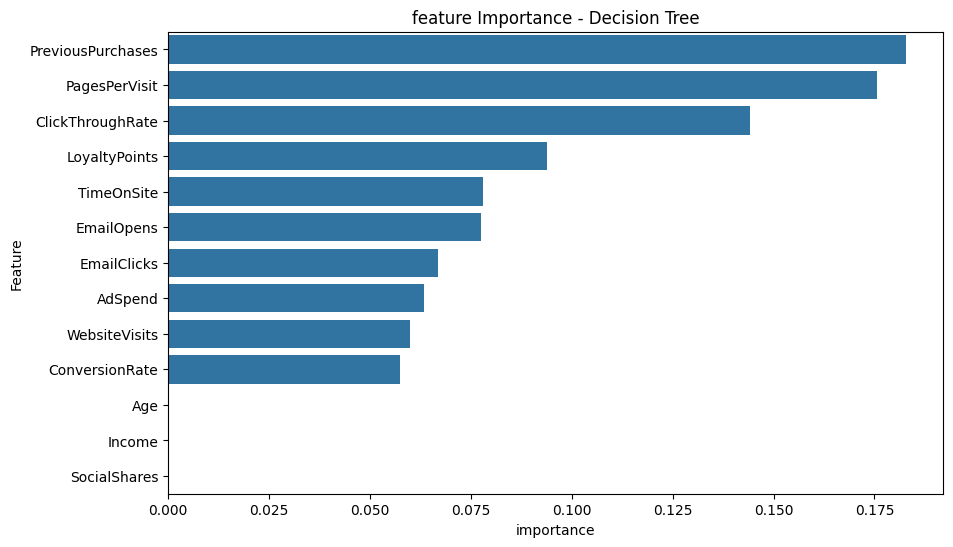

In [49]:
import seaborn as sns
import matplotlib.pyplot as plt

feature_importance = feature_importance.sort_values(
    by='importance',
    ascending=False
)
plt.figure(figsize=(10,6))

sns.barplot(
    data=feature_importance,
    x='importance',
    y='Feature'
)
plt.title('feature Importance - Decision Tree')

plt.show()

## Modelo Final 

Foram avaliados dois modelos ML: Regressao logistica e Arvore de Decisao.

A arvore mostrou melhor capacidade para identificar clientes que nao converteram. Alem disso, a analise de importancia das variaveis permitiu identificar quais fatores tiveram maior influencia nas previsoes do modelo.

dessa forma, a arvore de decisao foi considerada o modelo mais adequado para este conjuto de dados. 

## Machine Learning Models Used 

### Logistic Regression

Used when the goal is to predict a binary outcome, such as YES/NO or 0/1.

Examples:

- Will a customer convert?
- Will a member renew?
- Will a user register for an event?

Advantages:

- Single to implement
- Easy to interpret
- Good baseline model for classification problems

### Decision Tree

Used when the goal is to create predictions based on a series of decision rules.

Examples:

- Which customers are most likely to convert?
- What factors influence member renewal?

Advantages:

- Easy to visualize and explain
- Identifies the most important variables
- Produces business-friendly decision rules

### Random Forest

Used when higher predictive performance is desired.

Examples:

- Conversion prediction
- Customer churn prediction
- Membership renewal prediction

Advantages:

- More accurate than a single Decision tree
- Reduces overfitting
- Handles complex relationships between variables

Disadvantages:

- Harder to explain to business stakeholders
- Less interpretable than a Decision Tree

### When to Use Each Model

- **Logistic Regression:** When you need a single and explainable model for YES/NO predictions.
- **Decision Tree:** When you want to understand the decision-making process and feature importance.
- **Random Forest:** When prediction accuracy is the main objective and interpretability is less important.

# Principais Descobertas

- A taxa de conversão foi de aproximadamente 87%.
- Clientes mais engajados apresentaram maiores taxas de conversão.
- PreviousPurchases, PagesperVisit e ClickThroughRate foram os fatores mais importantes para prever conversões.
- Age, Income e socialShares tiveram pouca influência na conversão.
- A árvore de decisão apresentou desempenho mais equilibrado que a regressão logística.

# Recomendaçoes

- Investir em campanhas de engajamento por e-mail.
- Melhorar a experiência do website
- Fortalecer programas de fidelização
- Utilizar segmentação baseada em comportamento. 

# Conclusão

- Os resultados indicam que variáveis comportamentais tiveram maior influência na conversão do que características demográficas.

- Além disso, a árvore de decisão apresentou o desempenho mais equilibrado entre os modelos avaliados, permitindo identificar melhor clientes convertidos e não convertidos. 

# Limitaçoes

- O dataset apresentou desbalanceamento na variável de conversão.
- Apenas dois modelos de machine learning foram avaliados.
- Fatores externos não disponíveis nos dados podem influenciar a conversão.